# Import libraries

In [1]:
# File and directory management
import os
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Image processing
from PIL import Image

# Visualization
import matplotlib.pyplot as plt

# Progress monitoring
from tqdm.auto import tqdm

# PyTorch
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Configure project directories

In [2]:
# Project root
PROJECT_ROOT = Path.cwd().parent

# Original CelebA dataset
DATASET_DIR = PROJECT_ROOT / "data" / "celeba"/"raw"

# Image directory
IMAGE_DIR = DATASET_DIR / "img_align_celeba"

# Processed data directory
PROCESSED_DIR = PROJECT_ROOT / "data" / "celeba" /"processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Define annotation file paths

In [3]:
ANNOTATION_FILES = {
    "identity": DATASET_DIR / "identity_CelebA.txt",
    "partition": DATASET_DIR / "list_eval_partition.txt",
    "attributes": DATASET_DIR / "list_attr_celeba.txt",
    "bbox": DATASET_DIR / "list_bbox_celeba.txt",
    "landmarks": DATASET_DIR / "list_landmarks_align_celeba.txt"
}

# Validate dataset structure

In [4]:
# Required directories
assert DATASET_DIR.exists(), "CelebA dataset directory not found!"

assert IMAGE_DIR.exists(), "Image directory not found!"

# Required annotation files
for name in ["identity", "partition"]:
    assert ANNOTATION_FILES[name].exists(), (
        f"Missing annotation: {ANNOTATION_FILES[name]}"
    )

print("Dataset structure validation successful!")

Dataset structure validation successful!


# Inspect image collection

In [5]:
# Count images without loading them into memory
image_count = sum(
    1 for _ in IMAGE_DIR.glob("*.jpg")
)

# Display sample filenames
sample_images = sorted(IMAGE_DIR.glob("*.jpg"))[:10]

print("Total images:", image_count)

print("\nSample image filenames:")

for image_path in sample_images:
    print(image_path.name)

Total images: 202599

Sample image filenames:
000001.jpg
000002.jpg
000003.jpg
000004.jpg
000005.jpg
000006.jpg
000007.jpg
000008.jpg
000009.jpg
000010.jpg


# Load identity annotations

In [6]:
identity_df = pd.read_csv(
    ANNOTATION_FILES["identity"],
    sep=r"\s+",
    header=None,
    names=["filename", "identity_id"]
)

print("Shape:", identity_df.shape)

identity_df.head(10)

Shape: (202599, 2)


,filename,identity_id
0,000001.jpg,2880
1,000002.jpg,2937
2,000003.jpg,8692
3,000004.jpg,5805
4,000005.jpg,9295
5,000006.jpg,4153
6,000007.jpg,9040
7,000008.jpg,6369
8,000009.jpg,3332
9,000010.jpg,612


# Load partition annotations

In [7]:
partition_df = pd.read_csv(
    ANNOTATION_FILES["partition"],
    sep=r"\s+",
    header=None,
    names=["filename", "partition_id"]
)

print("Shape:", partition_df.shape)

partition_df.head(10)

Shape: (202599, 2)


,filename,partition_id
0,000001.jpg,0
1,000002.jpg,0
2,000003.jpg,0
3,000004.jpg,0
4,000005.jpg,0
5,000006.jpg,0
6,000007.jpg,0
7,000008.jpg,0
8,000009.jpg,0
9,000010.jpg,0


In [8]:
print("Identity annotation statistics:\n")

print("Total records:", len(identity_df))
print("Unique identities:", identity_df["identity_id"].nunique())
print("Unique filenames:", identity_df["filename"].nunique())

print("\nPartition annotation statistics:\n")

print("Total records:", len(partition_df))
print("Unique filenames:", partition_df["filename"].nunique())
print("Partition values:", sorted(partition_df["partition_id"].unique()))

Identity annotation statistics:

Total records: 202599
Unique identities: 10177
Unique filenames: 202599

Partition annotation statistics:

Total records: 202599
Unique filenames: 202599
Partition values: [np.int64(0), np.int64(1), np.int64(2)]


# Check missing values and duplicates

In [9]:
print("IDENTITY ANNOTATIONS")
print("--------------------")

print("Missing values:")
print(identity_df.isnull().sum())

print("\nDuplicate filenames:")
print(identity_df["filename"].duplicated().sum())


print("\nPARTITION ANNOTATIONS")
print("---------------------")

print("Missing values:")
print(partition_df.isnull().sum())

print("\nDuplicate filenames:")
print(partition_df["filename"].duplicated().sum())

IDENTITY ANNOTATIONS
--------------------
Missing values:
filename       0
identity_id    0
dtype: int64

Duplicate filenames:
0

PARTITION ANNOTATIONS
---------------------
Missing values:
filename        0
partition_id    0
dtype: int64

Duplicate filenames:
0


# Understand identity distribution

In [10]:
identity_distribution = (
    identity_df["identity_id"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of unique identities:", len(identity_distribution))

print("\nImages belonging to the most frequent identities:")

display(identity_distribution.head(10))

Number of unique identities: 10177

Images belonging to the most frequent identities:


identity_id
2820    35
3782    35
3227    35
3699    34
3745    34
9152    32
8968    32
9256    32
2114    31
9840    31
Name: count, dtype: int64

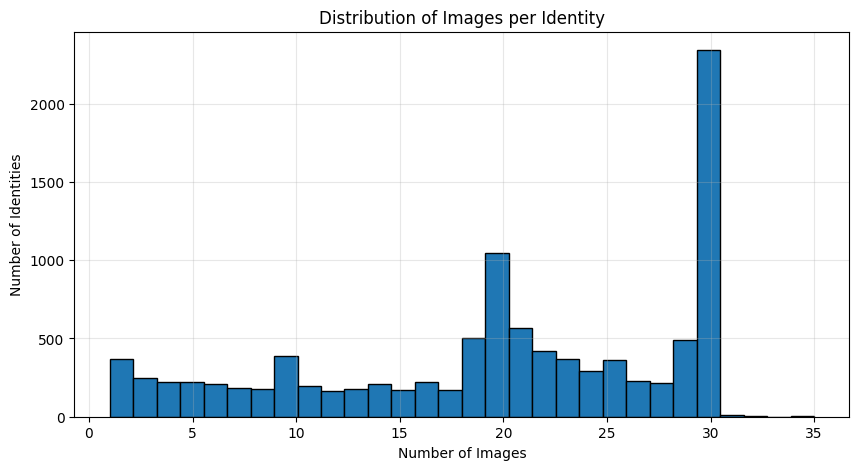

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(
    identity_distribution.values,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Images per Identity")
plt.xlabel("Number of Images")
plt.ylabel("Number of Identities")

plt.grid(alpha=0.3)
plt.show()

# Merge identity and partition annotations

In [12]:
# Merge identity and partition annotations
dataset_df = pd.merge(
    identity_df,
    partition_df,
    on="filename",
    how="inner",
    validate="one_to_one"
)

print("Dataset shape:", dataset_df.shape)

display(dataset_df.head(10))

Dataset shape: (202599, 3)


,filename,identity_id,partition_id
0,000001.jpg,2880,0
1,000002.jpg,2937,0
2,000003.jpg,8692,0
3,000004.jpg,5805,0
4,000005.jpg,9295,0
5,000006.jpg,4153,0
6,000007.jpg,9040,0
7,000008.jpg,6369,0
8,000009.jpg,3332,0
9,000010.jpg,612,0


# Generate image paths and split datasets

In [13]:
# Generate image paths
dataset_df["image_path"] = dataset_df["filename"].apply(
    lambda filename: str(IMAGE_DIR / filename)
)

# Separate datasets
train_df = dataset_df[
    dataset_df["partition_id"] == 0
].copy()

validation_df = dataset_df[
    dataset_df["partition_id"] == 1
].copy()

test_df = dataset_df[
    dataset_df["partition_id"] == 2
].copy()

# Reset indices
train_df.reset_index(drop=True, inplace=True)
validation_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print("Training images  :", len(train_df))
print("Validation images:", len(validation_df))
print("Testing images   :", len(test_df))

Training images  : 162770
Validation images: 19867
Testing images   : 19962


In [14]:
train_df

,filename,identity_id,partition_id,image_path
0,000001.jpg,2880,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
1,000002.jpg,2937,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
2,000003.jpg,8692,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
3,000004.jpg,5805,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
4,000005.jpg,9295,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
...,...,...,...,...
162765,162766.jpg,4414,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
162766,162767.jpg,4778,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
162767,162768.jpg,7391,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...
162768,162769.jpg,8610,0,Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE ...


In [15]:
# Required CSV columns
csv_columns = [
    "filename",
    "image_path",
    "identity_id"
]

# Output paths
train_csv_path = PROCESSED_DIR / "train.csv"
validation_csv_path = PROCESSED_DIR / "validation.csv"
test_csv_path = PROCESSED_DIR / "test.csv"

# Save CSV files
train_df[csv_columns].to_csv(train_csv_path, index=False)

validation_df[csv_columns].to_csv(validation_csv_path, index=False)

test_df[csv_columns].to_csv(test_csv_path, index=False)


print("\nSaved files:")
print(train_csv_path)
print(validation_csv_path)
print(test_csv_path)


Saved files:
Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\data\celeba\processed\train.csv
Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\data\celeba\processed\validation.csv
Y:\Python\AI ML\Month 2\week 8-NLP\45 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)\data\celeba\processed\test.csv


In [16]:
len(train_df.groupby('identity_id').filter(lambda x: len(x) >= 20)['identity_id'].unique())

5103

# Identity filtering — Minimum 20 images

In [17]:
MIN_IMAGES_PER_IDENTITY = 20

train_identity_counts = train_df["identity_id"].value_counts()

eligible_identities = train_identity_counts[
    train_identity_counts >= MIN_IMAGES_PER_IDENTITY
].index

print("Eligible identities:", len(eligible_identities))

Eligible identities: 5103


In [18]:
train_df = train_df[
    train_df["identity_id"].isin(eligible_identities)
].copy()

train_df.reset_index(drop=True, inplace=True)

print("Training images:", len(train_df))
print("Training identities:", train_df["identity_id"].nunique())

Training images: 131442
Training identities: 5103


In [19]:
train_df[
    ["filename", "image_path", "identity_id"]
].to_csv(train_csv_path, index=False)

# Image Preprocessing and Transformations

In [20]:
IMAGE_SIZE = 112

MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)

BATCH_SIZE = 64

In [21]:
train_transform = transforms.Compose([

    # Standardize image dimensions
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # Geometric augmentation
    transforms.RandomHorizontalFlip(p=0.5),

    # Color augmentation
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    # Convert PIL image to tensor
    transforms.ToTensor(),

    # Normalize pixel values to [-1, 1]
    transforms.Normalize(MEAN, STD)
])


eval_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(MEAN, STD)
])

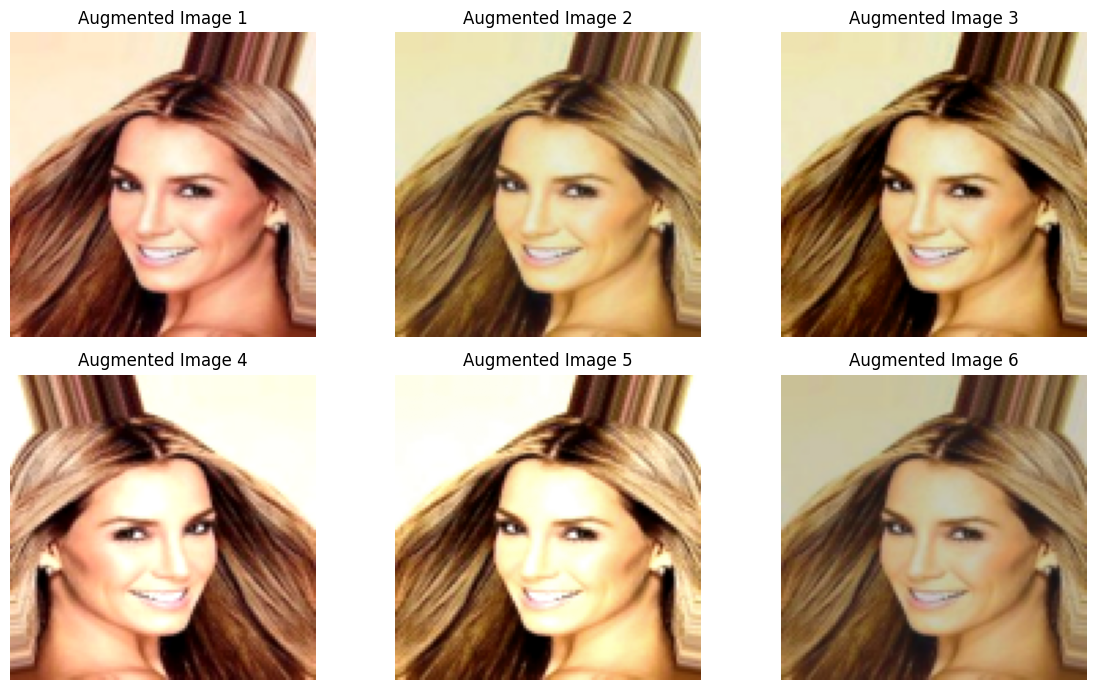

In [22]:
sample_path = train_df.iloc[0]["image_path"]

image = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(12, 7))

for i in range(6):

    augmented_image = train_transform(image)

    # Convert tensor to display format
    display_image = augmented_image.permute(1, 2, 0).numpy()

    # Reverse normalization
    display_image = (display_image * 0.5) + 0.5

    display_image = np.clip(display_image, 0, 1)

    plt.subplot(2, 3, i + 1)

    plt.imshow(display_image)
    plt.title(f"Augmented Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Original image
image = Image.open(sample_path).convert("RGB")

# Evaluation transformation
processed_image = eval_transform(image)

print("Original dimensions:", image.size)
print("Processed tensor shape:", processed_image.shape)
print("Data type:", processed_image.dtype)

print("Minimum pixel value:", processed_image.min().item())
print("Maximum pixel value:", processed_image.max().item())

Original dimensions: (178, 218)
Processed tensor shape: torch.Size([3, 112, 112])
Data type: torch.float32
Minimum pixel value: -1.0
Maximum pixel value: 1.0


# Custom PyTorch Dataset

In [24]:
identity_to_class = {
    identity_id: class_id
    for class_id, identity_id in enumerate(
        sorted(train_df["identity_id"].unique())
    )
}

NUM_CLASSES = len(identity_to_class)

print("Number of training classes:", NUM_CLASSES)

Number of training classes: 5103


In [25]:
class CelebADataset(Dataset):

    def __init__(self, dataframe, transform=None, label_mapping=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        identity_id = int(row["identity_id"])

        if self.transform:
            image = self.transform(image)

        if self.label_mapping is not None:
            label = self.label_mapping[identity_id]
        else:
            label = identity_id

        return image, label

In [26]:
train_dataset = CelebADataset(
    dataframe=train_df,
    transform=train_transform,
    label_mapping=identity_to_class
)

validation_dataset = CelebADataset(
    dataframe=validation_df,
    transform=eval_transform
)

test_dataset = CelebADataset(
    dataframe=test_df,
    transform=eval_transform
)

In [27]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Identity class:", label)
print("Image dtype:", image.dtype)

Image shape: torch.Size([3, 112, 112])
Identity class: 1529
Image dtype: torch.float32


#  DataLoaders and Batch Verification

In [28]:
BATCH_SIZE = 32
NUM_WORKERS = 0

PIN_MEMORY = torch.cuda.is_available()

In [29]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [30]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Images shape: torch.Size([32, 3, 112, 112])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64


In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Batch memory:", images.element_size() * images.nelement() / (1024 ** 2), "MB")

Device: cuda
Batch memory: 4.59375 MB


# Save Metadata and Final Dataset Validation

In [32]:
import json

identity_to_class_json = {
    int(identity_id): int(class_id)
    for identity_id, class_id in identity_to_class.items()
}

mapping_path = PROCESSED_DIR / "identity_to_class.json"

with open(mapping_path, "w") as file:
    json.dump(identity_to_class_json, file, indent=4)

In [33]:
dataset_config = {
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_classes": NUM_CLASSES,
    "min_images_per_identity": MIN_IMAGES_PER_IDENTITY,
    "mean": MEAN,
    "std": STD
}

config_path = PROCESSED_DIR / "dataset_config.json"

with open(config_path, "w") as file:
    json.dump(dataset_config, file, indent=4)

In [34]:
print("TRAINING")
print("Images:", len(train_dataset))
print("Identities:", NUM_CLASSES)

print("\nVALIDATION")
print("Images:", len(validation_dataset))

print("\nTEST")
print("Images:", len(test_dataset))

print("\nDATALOADERS")
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

TRAINING
Images: 131442
Identities: 5103

VALIDATION
Images: 19867

TEST
Images: 19962

DATALOADERS
Training batches: 4107
Validation batches: 621
Test batches: 624


In [35]:
%%writefile ../src/dataset.py

import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset


class CelebADataset(Dataset):

    def __init__(self, dataframe, transform=None, label_mapping=None):

        if isinstance(dataframe, str):
            dataframe = pd.read_csv(dataframe)

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        identity_id = int(row["identity_id"])

        if self.transform:
            image = self.transform(image)

        if self.label_mapping is not None:
            label = self.label_mapping[identity_id]
        else:
            label = identity_id

        return image, label

Overwriting ../src/dataset.py


In [36]:
%%writefile ../src/transforms.py

from torchvision import transforms


def get_train_transforms(image_size=112):

    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2,
            hue=0.05
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.5, 0.5, 0.5),
            std=(0.5, 0.5, 0.5)
        )
    ])


def get_eval_transforms(image_size=112):

    return transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.5, 0.5, 0.5),
            std=(0.5, 0.5, 0.5)
        )
    ])

Overwriting ../src/transforms.py


In [37]:
%%writefile ../src/__init__.py

from .dataset import CelebADataset
from .transforms import get_train_transforms, get_eval_transforms

Overwriting ../src/__init__.py


In [38]:
import sys

sys.path.insert(0, str(PROJECT_ROOT))

from src import (
    CelebADataset,
    get_train_transforms,
    get_eval_transforms
)

print("All source modules imported successfully!")

All source modules imported successfully!


In [39]:
train_transform = get_train_transforms(IMAGE_SIZE)
eval_transform = get_eval_transforms(IMAGE_SIZE)

train_dataset = CelebADataset(
    train_df,
    transform=train_transform,
    label_mapping=identity_to_class
)

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Identity class:", label)

Image shape: torch.Size([3, 112, 112])
Identity class: 1529
